# Dataframe

In [7]:
# Use Case: E-Commerce Order Management
import pandas as pd
orders = pd.DataFrame({
    #column Name:values
"Order_ID": [1001, 1002, 1003,None],
"Category": ["Electronics", "Clothing","Grocery","Electronics"],
"Order_Amount": [85000, 4500, 3200, 125000],
"Delivery_Days": [3, 5, 2, 8], 
"Rating": [5, 4, 5, 2] 
})
print(orders)

   Order_ID     Category  Order_Amount  Delivery_Days  Rating
0    1001.0  Electronics         85000              3       5
1    1002.0     Clothing          4500              5       4
2    1003.0      Grocery          3200              2       5
3       NaN  Electronics        125000              8       2


# Loading and Inspecting Data

### Data Loading

In [8]:
import seaborn as sns
df_iris = sns.load_dataset("iris")

In [9]:
df_titanic = sns.load_dataset("titanic")

In [10]:
df_tips = sns.load_dataset("tips")

##### Numpy to Dataframe

In [11]:
#Example use case

#Suppose you use NumPy to generate data:

import numpy as np


arr = np.random.randint(0, 100, size=(5, 3))

#You get something like:

# [[45 78 32]
#  [12 56 91]
#  [67 23 44]
#  [89 34 76]
#  [21 90 55]]

#NumPy is great for creating and calculating numerical data.

#But now you want meaningful column names:
df = pd.DataFrame(
    arr,
    columns=["Math", "AI", "Database"]
)
df

,Math,AI,Database
0,44,1,35
1,27,74,64
2,30,23,16
3,52,45,81
4,8,0,94


In [12]:
import numpy as np
arr = np.array([[1, 2], [3, 4]])
df = pd.DataFrame(arr, columns=["A", "B"])
print(df)

   A  B
0  1  2
1  3  4


### Initial Inspection

In [13]:
df_iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


##### data dimensionality

In [14]:
df_iris.shape

(150, 5)

##### List all columns

In [15]:
df_iris.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [16]:
col=df_iris.columns.to_list()

In [17]:
col[0]

'sepal_length'

In [18]:
df_iris["petal_length"]

0      1.4
1      1.4
2      1.3
3      1.5
4      1.4
      ... 
145    5.2
146    5.0
147    5.2
148    5.4
149    5.1
Name: petal_length, Length: 150, dtype: float64

##### understand the size, structure, and data types of the dataset

In [19]:
df_iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


## Understanding & Cleaning Data

#### Handling Missing Values

In [20]:
df_titanic.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [21]:
titanic_processed = df_titanic.copy()

titanic_processed["age"] = titanic_processed["age"].fillna(
    titanic_processed["age"].mean()
)
titanic_processed["embarked"] = titanic_processed["embarked"].fillna(
    titanic_processed["embarked"].mode()[0]
)
titanic_processed["embark_town"] = titanic_processed["embark_town"].fillna(
    titanic_processed["embark_town"].mode()[0]
)
titanic_processed.drop(columns=["deck"], inplace=True)

In [22]:
titanic_processed.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

##### Handling Duplicate Records

In [23]:
import numpy as np
arr = np.array([[10542, 8500,"Electronics"], [10543, 9000, "Clothing"]])
df = pd.DataFrame(arr, columns=["Order_ID", "Amount", "Category"])
print(df)

  Order_ID Amount     Category
0    10542   8500  Electronics
1    10543   9000     Clothing


In [24]:
print(arr) #converted to strings as numpy array can only hold one data type, so it converted all elements to strings to maintain consistency.
print(arr.dtype)

[['10542' '8500' 'Electronics']
 ['10543' '9000' 'Clothing']]
<U21


In [25]:
print(df.dtypes)

Order_ID    str
Amount      str
Category    str
dtype: object


In [26]:
df = pd.DataFrame({
    "Order_ID": [10542, 10543,10542],
    "Amount": [8500, 9000, 8500],
    "Category": ["Electronics", "Clothing", "Electronics"]
})
df

,Order_ID,Amount,Category
0,10542,8500,Electronics
1,10543,9000,Clothing
2,10542,8500,Electronics


In [27]:
# Find duplicate rows in the DataFrame
df.duplicated().sum() # only checks for duplicate rows, not individual columns. It returns the count of duplicate rows in the DataFrame.

np.int64(1)

In [28]:
df = df.drop_duplicates() # Remove

In [29]:
df.duplicated().sum() # Verify

np.int64(0)

##### Datatype Correction

In [30]:
# Use Case: E-Commerce Revenue
df = pd.DataFrame({
    "Order_ID": [1001, 1002,1003,1004],
    "Order_Amount": [8500, 4500, "unknown", 12500],
})
df

,Order_ID,Order_Amount
0,1001,8500
1,1002,4500
2,1003,unknown
3,1004,12500


In [31]:
print(df.dtypes)

Order_ID         int64
Order_Amount    object
dtype: object


In [32]:
df["Order_Amount"].astype(int) # Incorrect Approach: This will raise an error because the column contains a non-numeric value ("unknown"). You need to handle non-numeric values before converting the column to integers.

ValueError: invalid literal for int() with base 10: 'unknown'

In [ ]:
# correct Approach: Use pd.to_numeric with errors='coerce' 
# to convert non-numeric values to NaN, then handle them as needed (e.g., fill with a default value or drop them).
df["Order_Amount"] = pd.to_numeric(
df["Order_Amount"],
errors="coerce"
)

In [ ]:
print(df.dtypes)

Order_ID          int64
Order_Amount    float64
dtype: object


##### Handling Inconsistent Categories

In [ ]:
# usecase: Food Delivery Traffic Analysis
# Use Case: E-Commerce Revenue
df_traffic = pd.DataFrame({
    "ID": [1001, 1002,1003,1004,1005,1006],
    "Traffic":["High", "high", "HIGH", "Medium","medium","Low"],
    "Delivery_Time": [48, 55, 50, 35, 37, 28]
})
df_traffic

,ID,Traffic,Delivery_Time
0,1001,High,48
1,1002,high,55
2,1003,HIGH,50
3,1004,Medium,35
4,1005,medium,37
5,1006,Low,28


In [ ]:
df_traffic["Traffic"].value_counts()

Traffic
High      1
high      1
HIGH      1
Medium    1
medium    1
Low       1
Name: count, dtype: int64

In [ ]:
# Standardize text
df_traffic["Traffic"] = df_traffic["Traffic"].str.lower()

In [ ]:
df_traffic["Traffic"].value_counts()

Traffic
high      3
medium    2
low       1
Name: count, dtype: int64

##### Unique Values And Feature Cardinality

In [ ]:
df.nunique()

ID         6
Traffic    3
dtype: int64

In [ ]:
df["Traffic"].nunique() # for a specific feature

3

## Descriptive Statistics

##### Statistical Summary

In [ ]:
df_iris.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


##### Column-Wise Statistics

In [ ]:
df_iris["petal_length"].mean()

np.float64(3.7580000000000005)

In [ ]:
round(df_iris["petal_length"].std(), 2)

np.float64(1.77)

## Advanced EDA Functions

In [ ]:
# Use Case: E-Commerce Revenue
df = pd.DataFrame({
    "Order_ID": [1001, 1002,1003,1004,1005,1006,1007,1008,1009,1010],
    "Category": ["Electronics", "Electronics", "Clothing", "Clothing","clothing", "Grocery","Book","Book","Book","Book"],
})
df

,Order_ID,Category
0,1001,Electronics
1,1002,Electronics
2,1003,Clothing
3,1004,Clothing
4,1005,clothing
5,1006,Grocery
6,1007,Book
7,1008,Book
8,1009,Book
9,1010,Book


In [ ]:
# Use Case: E-Commerce Product Categories
df["Category"].value_counts()

Category
Book           4
Electronics    2
Clothing       2
clothing       1
Grocery        1
Name: count, dtype: int64

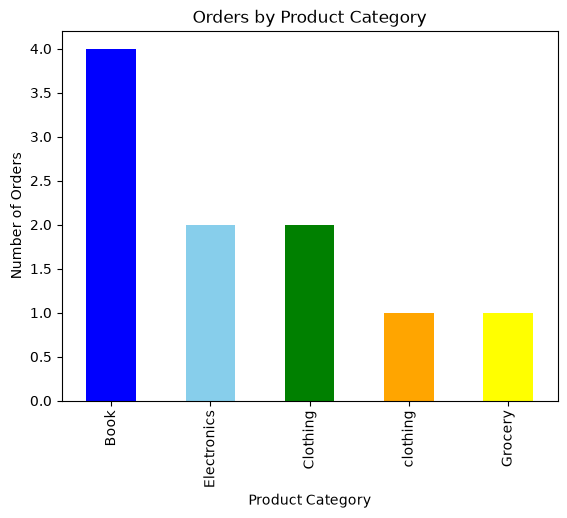

In [ ]:
import matplotlib.pyplot as plt
df["Category"].value_counts().plot(kind="bar", color=["blue", "skyblue", "green", "orange","yellow"])
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")
plt.title("Orders by Product Category")
plt.show()

##### Group Analysis

In [ ]:
df_iris.groupby('species').mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.428,1.462,0.246
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [ ]:
df_traffic

,ID,Traffic,Delivery_Time
0,1001,high,48
1,1002,high,55
2,1003,high,50
3,1004,medium,35
4,1005,medium,37
5,1006,low,28


In [ ]:
# UseCase: Food Delivery Performance Analysis
df_traffic.groupby("Traffic")["Delivery_Time"].mean()

Traffic
high      51.0
low       28.0
medium    36.0
Name: Delivery_Time, dtype: float64

#####  Correlation Analysis

In [ ]:
df_traffic

,ID,Traffic,Delivery_Time
0,1001,high,48
1,1002,high,55
2,1003,high,50
3,1004,medium,35
4,1005,medium,37
5,1006,low,28


For this particular column, this is better than one-hot encoding because low, medium, and high have a natural order.

###### Ordinal Encoding

In [ ]:
df_traffic["Traffic"] = df_traffic["Traffic"].map({
    "low": 1,
    "medium": 2,
    "high": 3
})
#ordinal, label, one-hot, binary

In [ ]:
corr_matrix = df_traffic.corr(numeric_only=True)
corr_matrix

,ID,Traffic,Delivery_Time
ID,1.000000,-0.916515,-0.870183
Traffic,-0.916515,1.000000,0.959560
Delivery_Time,-0.870183,0.959560,1.000000


<Axes: >

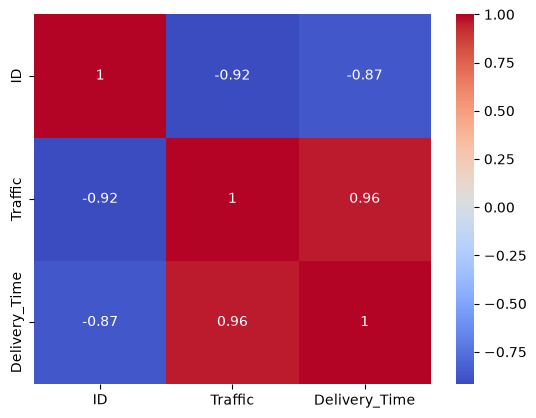

In [ ]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

### OR

In [ ]:
corr_matrix = df_traffic.drop(columns=["ID"]).corr(numeric_only=True)

corr_matrix

,Traffic,Delivery_Time
Traffic,1.00000,0.95956
Delivery_Time,0.95956,1.00000


<Axes: >

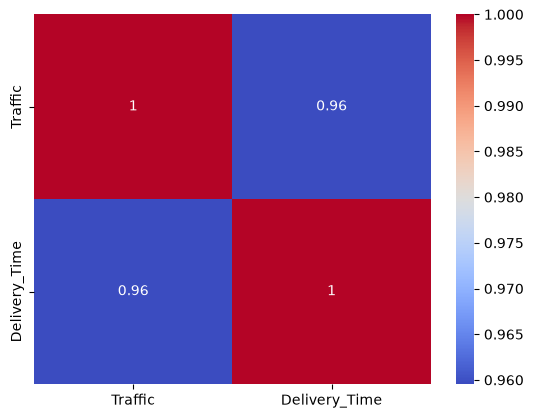

In [ ]:
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

if you're using this for a machine-learning project, such a high correlation could indicate that Traffic is an excellent predictor of Delivery_Time, but you should check the scatter plot and other variables to understand the relationship more completely.

Positive correlation (+)

Two variables tend to increase or decrease together.

Example:

Traffic ↑ → Delivery Time ↑
Traffic ↓ → Delivery Time ↓

The +0.96 means this relationship is very strongly positive.

Negative correlation (−)

One variable tends to increase while the other decreases.

Example:

Speed ↑ → Delivery Time ↓
Speed ↓ → Delivery Time ↑

##### Class Imbalance Analysis

In [ ]:
import pandas as pd

data = {
    "Transaction_ID": [9001, 9002, 9003, 9004],
    "Amount ": [1200, 85000, 3000, 150000],
    "Time": ["10:15 AM", "11:03 AM", "12:45 PM", "02:20 PM"],
    "Merchant": ["Grocery", "Electronics", "Fuel", "Jewelry"],
    "Is_Fraud": ["No", "No", "No", "Yes"]
}

df = pd.DataFrame(data)

df

,Transaction_ID,Amount,Time,Merchant,Is_Fraud
0,9001,1200,10:15 AM,Grocery,No
1,9002,85000,11:03 AM,Electronics,No
2,9003,3000,12:45 PM,Fuel,No
3,9004,150000,02:20 PM,Jewelry,Yes


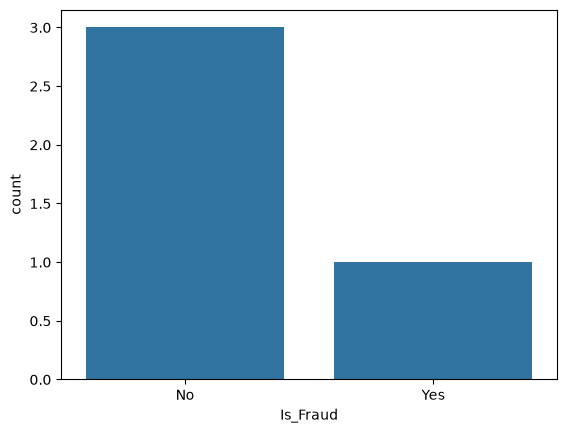

In [ ]:
df['Is_Fraud'].value_counts()
sns.countplot(x='Is_Fraud', data=df)
plt.show()

In [ ]:
titanic_processed["survived"].value_counts()

survived
0    549
1    342
Name: count, dtype: int64

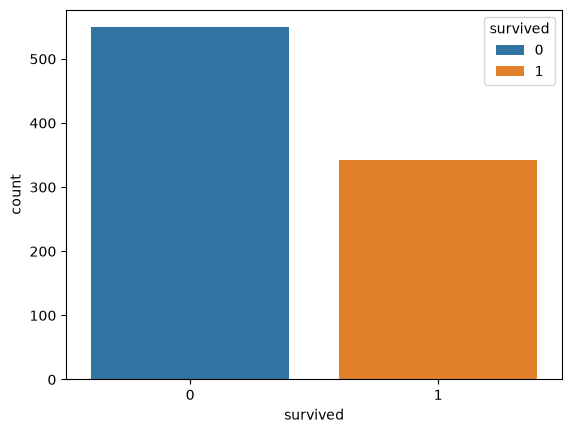

In [ ]:
sns.countplot(x="survived", data=titanic_processed, hue="survived")
plt.show()

##### Class Imbalance Handling through Random Under Sampling

In [ ]:
minority = titanic_processed[titanic_processed["survived"] == 1]
majority = titanic_processed[titanic_processed["survived"] == 0]

majority_downsampled = majority.sample(len(minority), random_state=42)

titanic_balanced = pd.concat([minority, majority_downsampled])

In [ ]:
titanic_processed.shape, titanic_balanced.shape


((891, 14), (684, 14))

In [ ]:
titanic_balanced["survived"].value_counts()

survived
1    342
0    342
Name: count, dtype: int64

Under-sampling is one possible solution, not automatically the best solution

## Data Visualization

##### Histogram (Distribution)

In [ ]:
data = {
    "Trip_Duration": [
        5, 7, 8, 10, 10, 12, 12, 13, 14, 15,
        15, 16, 17, 18, 18, 19, 20, 20, 21, 22,
        22, 23, 24, 25, 25, 26, 27, 28, 30, 30,
        32, 35, 36, 38, 40, 42, 45, 48, 50, 55
    ]
}

df = pd.DataFrame(data)

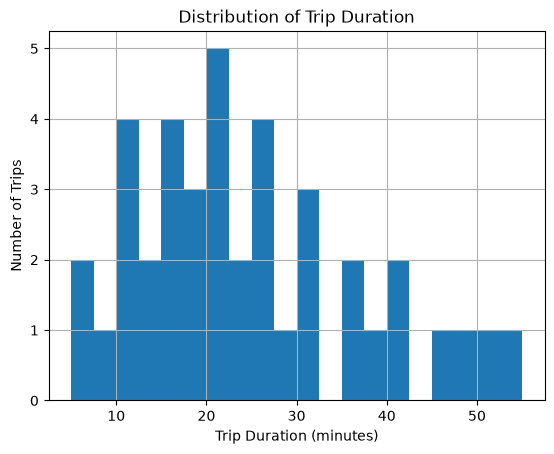

In [ ]:
#Use Case: Ride-Hailing Trip Duration
#A ride-hailing company wants to understand how long trips normally take.
df["Trip_Duration"].hist(bins=20)
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Duration")
plt.show()

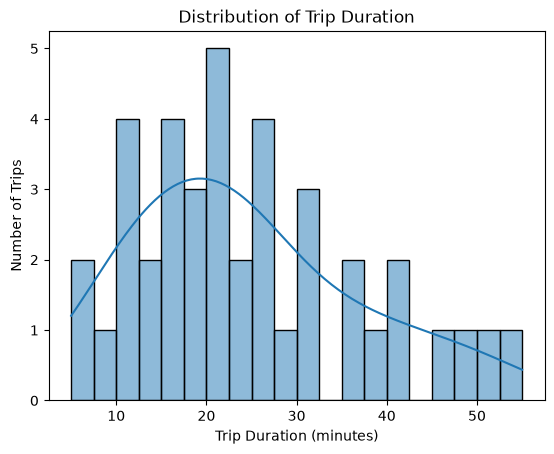

In [ ]:
# with seaborn
sns.histplot(df["Trip_Duration"], bins=20, kde=True)

plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Number of Trips")
plt.title("Distribution of Trip Duration")
plt.show()

##### Bar Chart (Categorical Data)

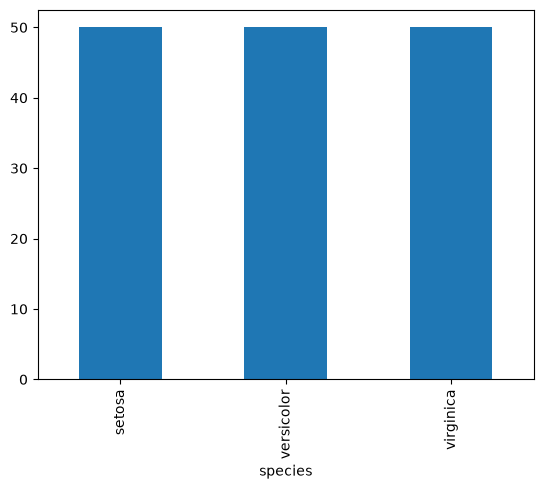

In [ ]:
df_iris['species'].value_counts().plot(kind='bar')
plt.show()

<Axes: xlabel='species', ylabel='count'>

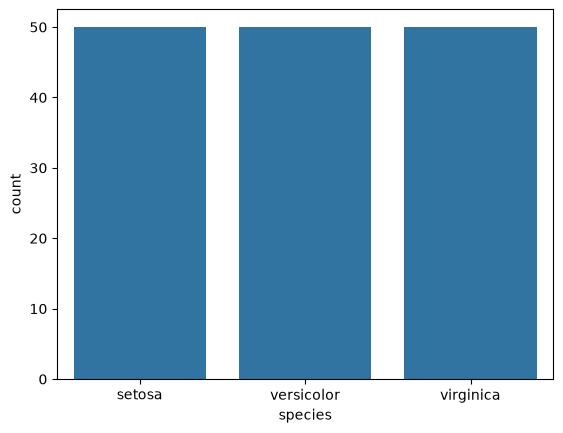

In [ ]:
#with seaborn
sns.countplot(x='species', data=df_iris)

##### Scatter Plot (Relationship Between Variables)

###### Use Case: Delivery Distance vs Delivery Time

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Delivery_Distance": [
        1, 2, 2.5, 3, 3.5,
        4, 4.5, 5, 5.5, 6,
        6.5, 7, 7.5, 8, 8.5,
        9, 10, 11, 12, 14
    ],
    "Delivery_Time": [
        15, 18, 20, 23, 25,
        27, 30, 32, 35, 37,
        39, 42, 43, 47, 49,
        52, 55, 59, 64, 70
    ]
}

df = pd.DataFrame(data)


###### Positive Correlation

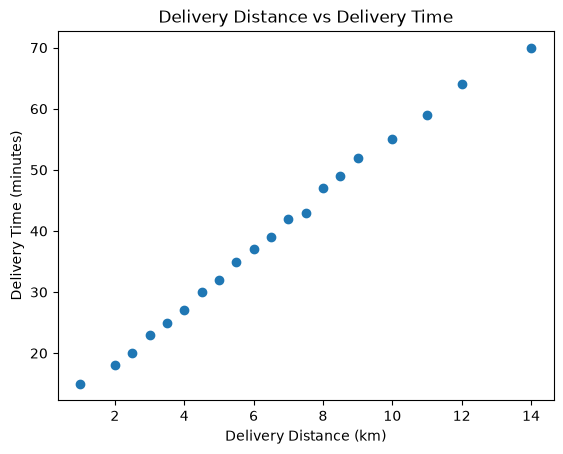

In [ ]:
# Scatterplot
plt.scatter(
    df["Delivery_Distance"],
    df["Delivery_Time"]
)

plt.xlabel("Delivery Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.title("Delivery Distance vs Delivery Time")
plt.show()

What students should observe

The points should generally move upward from left to right:

Distance ↑ → Delivery Time ↑

So this is an example of a positive correlation.

You can explain it to students as:

"If delivery distance increases, delivery time generally tends to increase as well. Therefore, the two variables have a positive relationship."

In [ ]:
correlation = df["Delivery_Distance"].corr(df["Delivery_Time"])

print("Correlation:", correlation)

Correlation: 0.9981473426023127


<Axes: xlabel='Delivery_Distance', ylabel='Delivery_Time'>

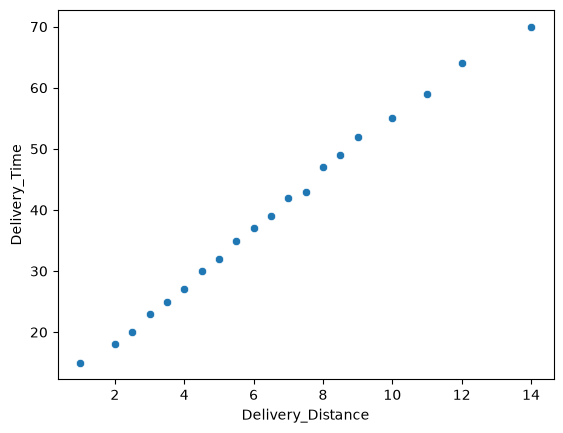

In [ ]:
#with seaborn
sns.scatterplot(
    x="Delivery_Distance",
    y="Delivery_Time",
    data=df
)

###### Use Case: Temperature vs Hot Chocolate Sales (Negative Correlation)

###### A cafe wants to investigate whether higher temperatures lead to fewer hot chocolate sales.

In [ ]:

data = {
    "Temperature": [
        5, 7, 9, 10, 12,
        14, 15, 17, 18, 20,
        21, 23, 24, 26, 27,
        29, 30, 32, 34, 36
    ],
    "Hot_Chocolate_Sales": [
        95, 90, 88, 82, 80,
        75, 72, 68, 65, 62,
        58, 55, 52, 48, 45,
        42, 38, 35, 30, 25
    ]
}

df = pd.DataFrame(data)


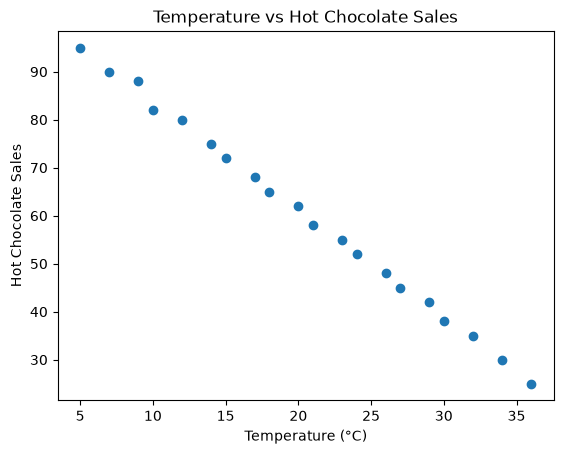

In [ ]:
# Scatterplot
plt.scatter(
    df["Temperature"],
    df["Hot_Chocolate_Sales"]
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Hot Chocolate Sales")
plt.title("Temperature vs Hot Chocolate Sales")
plt.show()

##### Outlier Identification Using IQR (Tips Dataset)

In [ ]:
def iqr_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    return lower, upper, outliers


In [ ]:
tb_lower, tb_upper, tb_outliers = iqr_outliers(df_tips["total_bill"])
tip_lower, tip_upper, tip_outliers = iqr_outliers(df_tips["tip"])

len(tb_outliers), len(tip_outliers)


(9, 9)

###### Boxplot

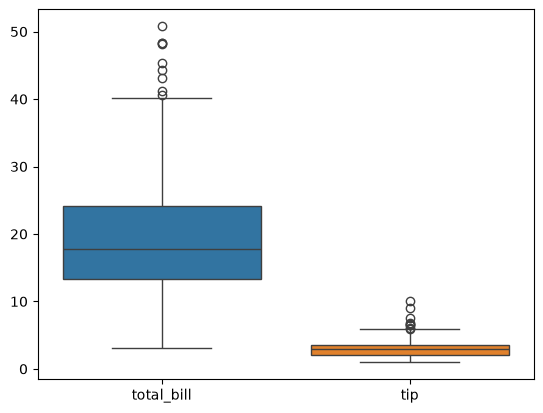

In [ ]:
sns.boxplot(data=df_tips[["total_bill", "tip"]])

plt.show()

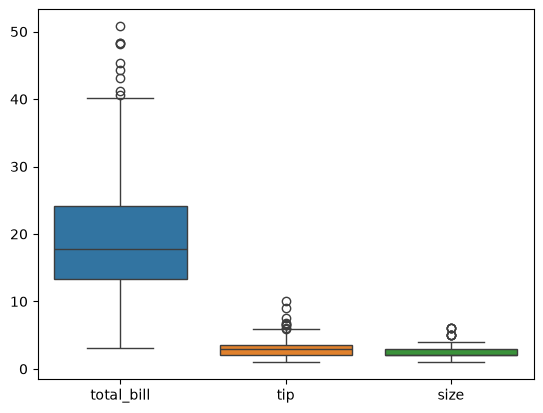

In [ ]:
sns.boxplot(data=df_tips)
plt.show()

##### Outlier Removal (IQR-Based)

In [ ]:
tips_clean = df_tips[
    (df_tips["total_bill"] >= tb_lower) & (df_tips["total_bill"] <= tb_upper) &
    (df_tips["tip"] >= tip_lower) & (df_tips["tip"] <= tip_upper)
]
print("Original shape:", df_tips.shape)
print("Cleaned shape:", tips_clean.shape)

#unique removed rows=9+9−overlap


Original shape: (244, 7)
Cleaned shape: (229, 7)


###### count the overlapping

In [ ]:
tb_outliers = df_tips[
    (df_tips["total_bill"] < tb_lower) |
    (df_tips["total_bill"] > tb_upper)
]

tip_outliers = df_tips[
    (df_tips["tip"] < tip_lower) |
    (df_tips["tip"] > tip_upper)
]

len(tb_outliers), len(tip_outliers), len(
    tb_outliers.index.intersection(tip_outliers.index)
)

(9, 9, 3)

###### Post-Processing Statistical Reassessment

In [ ]:
comparison = pd.DataFrame({
    "Before_Mean": df_tips[["total_bill", "tip"]].mean(),
    "After_Mean": tips_clean[["total_bill", "tip"]].mean(),
    "Before_Median": df_tips[["total_bill", "tip"]].median(),
    "After_Median": tips_clean[["total_bill", "tip"]].median(),
    "Before_STD": df_tips[["total_bill", "tip"]].std(),
    "After_STD": tips_clean[["total_bill", "tip"]].std()
})

comparison


,Before_Mean,After_Mean,Before_Median,After_Median,Before_STD,After_STD
total_bill,19.785943,18.476856,17.795,17.26,8.902412,7.212792
tip,2.998279,2.806332,2.900,2.71,1.383638,1.085224
